# 03 — Hipótesis longitudinal con datos reales (EMBED)

**El flujo central del TFG (O7/O8), ejecutable de principio a fin.** Para cada
paciente comparamos su exploración previa "normal" (t-1) con una exploración
posterior (t): en los pacientes *incidentes* la posterior es donde se
diagnostica la sospecha/malignidad; en los *control*, todas son normales.
Medimos dos señales topológicas:

- **Anticipación**: descriptores de persistencia de t-1 **sola** — ¿ya había señal *antes* del diagnóstico?
- **Deriva**: distancia *bottleneck* entre los diagramas de t-1 y t — ¿cuánto cambió la topología?

Reutiliza exactamente el mismo código que `scripts/download_embed_longitudinal.py`
y `scripts/embed_longitudinal_evaluation.py` (este notebook es la vista
interactiva; los scripts, la reproducción de un tirón). La parte de
clasificación aislada sobre CBIS-DDSM vive en `02_real_data_pipeline.ipynb`.

## Requisitos previos (una sola vez)

1. **Acceso a EMBED concedido** (es de acceso controlado; pasos en
   `docs/acceso_datasets_longitudinales.pdf`).
2. **Credenciales AWS** en `~/.aws/credentials`, perfil `[emory-embed]`.
   *Nunca* pongas las claves en el notebook ni en ningún fichero del repo.
3. **Tablas de metadatos** descargadas en `data/embed/` (celda 1 lo hace si faltan).
4. Dependencias: `pip install -r requirements.txt` (incluye `boto3` y
   `pylibjpeg`, necesario porque los DICOM de EMBED vienen comprimidos en
   JPEG Lossless).


## 0. Imports y configuración

In [1]:
from __future__ import annotations

import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(ROOT / "scripts"))

from src.topology import backend
import download_embed_longitudinal as dl
import embed_longitudinal_evaluation as ev

EMBED_DIR = ROOT / "data" / "embed"
print("Backend TDA activo:", backend())


Backend TDA activo: gudhi


## 1. Tablas de metadatos clínicos

Dos CSV pequeños (frente a los TB de imágenes): `clinical.csv` tiene una fila
por hallazgo con el BI-RADS (`asses`) de cada exploración, y
`metadata_reduced.csv` la ruta S3 de cada DICOM. Esta celda los descarga solo
si no están ya en `data/embed/`.

In [2]:
import boto3

EMBED_DIR.mkdir(parents=True, exist_ok=True)
TABLAS = {
    "clinical.csv": "tables/EMBED_OpenData_clinical.csv",
    "metadata_reduced.csv": "tables/EMBED_OpenData_metadata_reduced.csv",
}
faltan = {local: remota for local, remota in TABLAS.items() if not (EMBED_DIR / local).exists()}
if faltan:
    s3 = boto3.Session(profile_name="emory-embed", region_name="us-west-2").client("s3")
    for local, remota in faltan.items():
        print(f"Descargando {remota}...")
        s3.download_file("embed-dataset-open", remota, str(EMBED_DIR / local))
else:
    print("Tablas ya descargadas.")


Tablas ya descargadas.


## 2. Estructura longitudinal de la cohorte

¿Cuántos pacientes tienen 2+ exploraciones? ¿Cuántos son candidatos
*incidentes* (primera exploración Normal/Benigna → posterior
Sospechosa/Maligna) y cuántos *control*? Reutiliza
`dl._load_per_study_assessment` y `dl.select_pairs`.

23253 pacientes, 72770 exploraciones
14789 pacientes con 2+ exploraciones


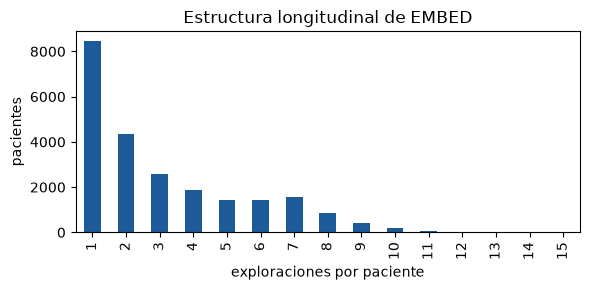

In [3]:
per_study = dl._load_per_study_assessment(EMBED_DIR / "clinical.csv")

exams = per_study.groupby("empi_anon").size()
print(f"{per_study['empi_anon'].nunique()} pacientes, {len(per_study)} exploraciones")
print(f"{(exams >= 2).sum()} pacientes con 2+ exploraciones")

fig, ax = plt.subplots(figsize=(6, 3))
exams.value_counts().sort_index().plot.bar(ax=ax, color="#1d5a99")
ax.set_xlabel("exploraciones por paciente"); ax.set_ylabel("pacientes")
ax.set_title("Estructura longitudinal de EMBED")
plt.tight_layout(); plt.show()


## 3. Selección del piloto (incidentes vs. control)

`dl.select_pairs` aplica la definición de O7/O8 sobre el BI-RADS por estudio
(`N`/`B` = normal/benigno; `S`/`M`/`K` = sospechoso/altamente
sugestivo/malignidad confirmada). Semilla fija → selección reproducible.

In [4]:
pares = dl.select_pairs(per_study, n_incident=50, n_control=50, seed=42)
print(f"{len(pares)} pacientes seleccionados "
      f"({sum(p['kind'] == 'incidente' for p in pares)} incidentes, "
      f"{sum(p['kind'] == 'control' for p in pares)} control)")
pares[:3]


100 pacientes seleccionados (50 incidentes, 50 control)


[{'empi_anon': 98673305,
  'kind': 'incidente',
  'acc_t0': np.int64(7195589007352545),
  'acc_t1': np.int64(9686447888524965)},
 {'empi_anon': 91984441,
  'kind': 'incidente',
  'acc_t0': np.int64(8350510711781002),
  'acc_t1': np.int64(9212866974027631)},
 {'empi_anon': 93311652,
  'kind': 'incidente',
  'acc_t0': np.int64(8802324043792482),
  'acc_t1': np.int64(8067277933937703)}]

## 4. Un par real (t-1, t) de cada clase

La mejor intuición de qué estamos midiendo: en el incidente, la exploración
t-1 fue leída como normal y en t hay un hallazgo; en el control, ambas son
normales.

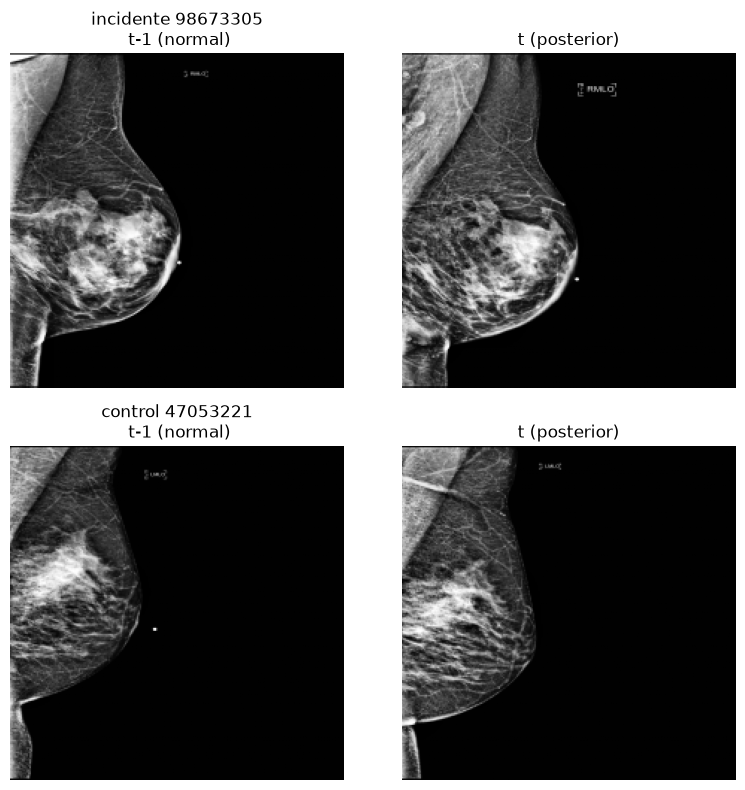

In [6]:
def _primer(kind):
    fila = manifest[manifest["kind"] == kind].iloc[0]
    return fila, ev._load_and_preprocess(ROOT / fila["path_t0"]), ev._load_and_preprocess(ROOT / fila["path_t1"])

fig, axes = plt.subplots(2, 2, figsize=(8, 8))
for i, kind in enumerate(["incidente", "control"]):
    fila, img_t0, img_t1 = _primer(kind)
    axes[i, 0].imshow(img_t0, cmap="gray"); axes[i, 0].set_title(f"{kind} {fila['empi_anon']}\n t-1 (normal)")
    axes[i, 1].imshow(img_t1, cmap="gray"); axes[i, 1].set_title("t (posterior)")
    for ax in axes[i]:
        ax.axis("off")
plt.tight_layout(); plt.show()


## 6. Señales topológicas de todo el piloto

Para cada paciente: diagrama de persistencia de t-1 y de t → vector de
anticipación (Persistence Image de t-1) y deriva (distancia bottleneck H0/H1
entre ambos, con `max_points=100`: los diagramas reales tienen miles de
puntos y sin recortar la distancia tarda ~2 min/par en vez de ~0.2 s;
recortar al top-100 por persistencia es la práctica estándar).

⏱️ ~2-4 min para 100 pacientes.

In [7]:
from src.topology import persistence_diagram, persistence_image_vector
from synthetic_longitudinal_validation import topological_drift

feats_t0, feats_drift, labels = [], [], []
for _, fila in manifest.iterrows():
    d0 = persistence_diagram(ev._load_and_preprocess(ROOT / fila["path_t0"]))
    d1 = persistence_diagram(ev._load_and_preprocess(ROOT / fila["path_t1"]))
    feats_t0.append(persistence_image_vector(d0, n_bins=6)[0])
    feats_drift.append(topological_drift(d0, d1, max_points=100))
    labels.append(1 if fila["kind"] == "incidente" else 0)

X_anticipacion = np.asarray(feats_t0)
X_deriva = np.asarray(feats_drift)
X_combinada = np.hstack([X_anticipacion, X_deriva])
y = np.asarray(labels)
print("anticipacion:", X_anticipacion.shape, " deriva:", X_deriva.shape)


anticipacion: (40, 72)  deriva: (40, 2)


## 7. ¿Separan las señales a incidentes de controles?

AUC por validación cruzada (5-fold) con Random Forest, igual que
`scripts/embed_longitudinal_evaluation.py`. Con ~100 pacientes esto sigue
siendo un **piloto**: mira las desviaciones típicas antes de sacar
conclusiones.

anticipación: AUC = 0.525 +/- 0.219


deriva      : AUC = 0.688 +/- 0.158


combinada   : AUC = 0.656 +/- 0.196


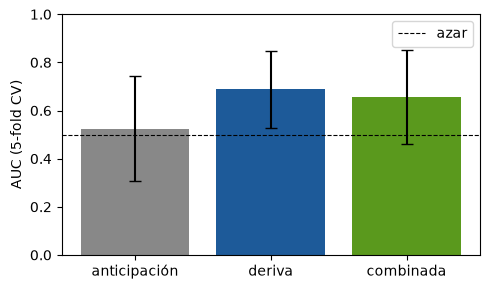

In [8]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score

resultados = {}
for nombre, X in [("anticipación", X_anticipacion), ("deriva", X_deriva), ("combinada", X_combinada)]:
    s = cross_val_score(RandomForestClassifier(n_estimators=300, random_state=42, class_weight="balanced"),
                        X, y, cv=5, scoring="roc_auc")
    resultados[nombre] = (s.mean(), s.std())
    print(f"{nombre:12s}: AUC = {s.mean():.3f} +/- {s.std():.3f}")

fig, ax = plt.subplots(figsize=(5, 3))
nombres = list(resultados)
medias = [resultados[n][0] for n in nombres]
stds = [resultados[n][1] for n in nombres]
ax.bar(nombres, medias, yerr=stds, capsize=4, color=["#888888", "#1d5a99", "#5a991d"])
ax.axhline(0.5, color="k", ls="--", lw=0.8, label="azar")
ax.set_ylabel("AUC (5-fold CV)"); ax.set_ylim(0, 1); ax.legend()
plt.tight_layout(); plt.show()


## 8. La distribución de la deriva, a ojo

Si la deriva separa, los incidentes deberían tener distancias t-1→t mayores
que los controles.

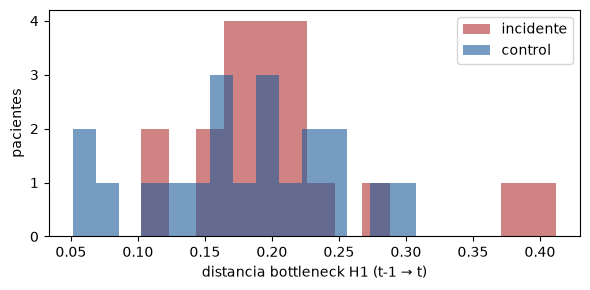

In [9]:
fig, ax = plt.subplots(figsize=(6, 3))
for etiqueta, color in [(1, "#b03030"), (0, "#1d5a99")]:
    vals = X_deriva[y == etiqueta, 1]  # distancia H1
    ax.hist(vals, bins=15, alpha=0.6, color=color,
            label="incidente" if etiqueta else "control")
ax.set_xlabel("distancia bottleneck H1 (t-1 → t)"); ax.set_ylabel("pacientes"); ax.legend()
plt.tight_layout(); plt.show()


## Lectura de los resultados y siguientes pasos

Con el piloto de 99 pacientes (resultados de referencia en
`results/embed_longitudinal_pilot.txt` y en la memoria, cap. 7):

- **Deriva ≈ 0.80 ± 0.06** — el cambio topológico entre t-1 y t es una señal
  real y robusta. Esperable: en t ya hay una lesión.
- **Anticipación ≈ 0.55 ± 0.10** — cerca del azar. La pregunta valiosa
  ("¿ya se veía antes?") sigue abierta: o el precursor es demasiado sutil
  para este descriptor (vista completa a 224×224), o no hay señal.

Siguientes pasos:
- Ampliar el piloto (`--n-incident 100 --n-control 100`...): hay 644
  incidentes y 7256 controles candidatos (issue #95).
- Probar descriptores más sensibles para la anticipación (mayor resolución,
  localización de la región sospechosa, otra filtración: ver
  `--filtration distance_transform` en `run_pipeline.py`).
